<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Training Perceptron ---
Epoch 1/10 - Errors: 2
Epoch 2/10 - Errors: 2
Epoch 3/10 - Errors: 3
Epoch 4/10 - Errors: 2
Epoch 5/10 - Errors: 1
Epoch 6/10 - Errors: 0
Epoch 7/10 - Errors: 0
Epoch 8/10 - Errors: 0
Epoch 9/10 - Errors: 0
Epoch 10/10 - Errors: 0


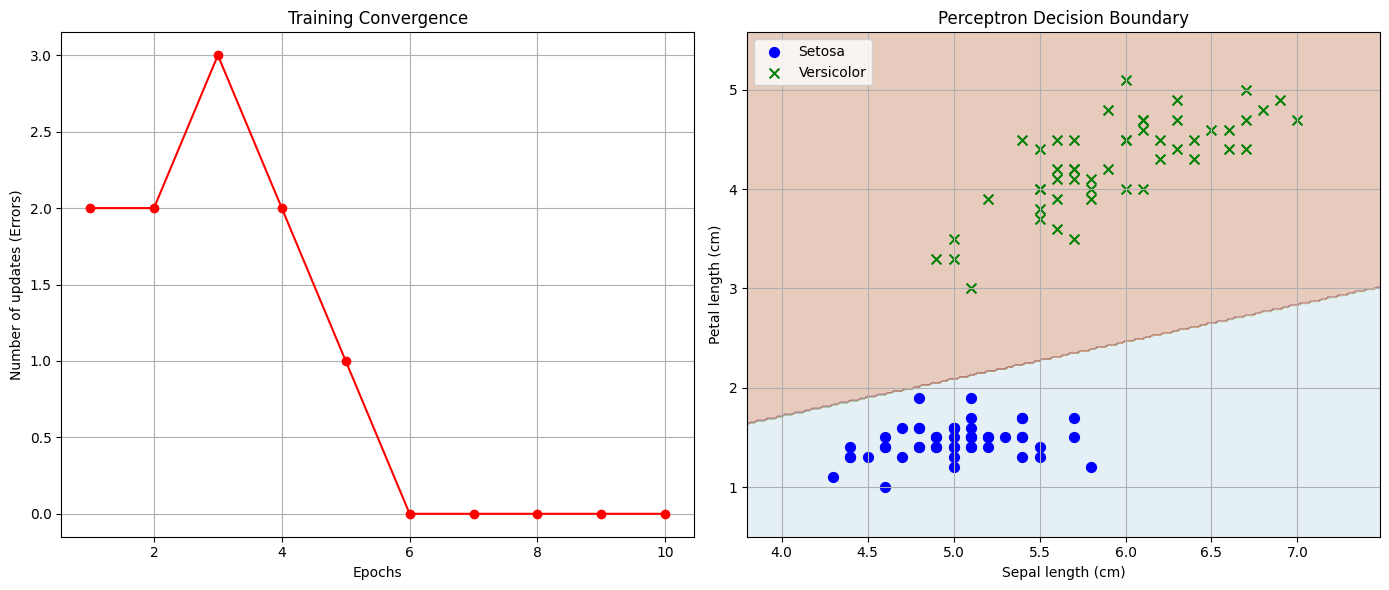

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets

# 1. Load the Iris dataset
iris = datasets.load_iris()
X = iris.data[:, [0, 2]]  # Sepal length and Petal length
y = iris.target

# Since Perceptron is a binary classifier, we select only Setosa (0) and Versicolor (1)
mask = (y == 0) | (y == 1)
X = X[mask]
y = y[mask]

# Map targets to -1 and 1 for the Perceptron algorithm
y = np.where(y == 0, -1, 1)

# 2. Implement the Perceptron Class from Scratch
class Perceptron:
    def __init__(self, learning_rate=0.1, epochs=10):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.errors = []

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.errors = []

        for epoch in range(self.epochs):
            epoch_errors = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.weights += update * xi
                self.bias += update
                epoch_errors += int(update != 0.0)
            self.errors.append(epoch_errors)
            print(f"Epoch {epoch+1}/{self.epochs} - Errors: {epoch_errors}")
        return self

    def net_input(self, X):
        return np.dot(X, self.weights) + self.bias

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

# 3. Train the model
print("--- Training Perceptron ---")
ppn = Perceptron(learning_rate=0.1, epochs=10)
ppn.fit(X, y)

# 4. Plot Decision Boundary and Training Progress
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot misclassifications over epochs
ax1.plot(range(1, len(ppn.errors) + 1), ppn.errors, marker='o', color='red')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Number of updates (Errors)')
ax1.set_title('Training Convergence')
ax1.grid(True)

# Plot decision boundary
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx1, xx2 = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = ppn.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
Z = Z.reshape(xx1.shape)

ax2.contourf(xx1, xx2, Z, alpha=0.3, cmap=plt.cm.Paired)
ax2.scatter(X[y == -1, 0], X[y == -1, 1], color='blue', marker='o', label='Setosa', s=50)
ax2.scatter(X[y == 1, 0], X[y == 1, 1], color='green', marker='x', label='Versicolor', s=50)
ax2.set_xlabel('Sepal length (cm)')
ax2.set_ylabel('Petal length (cm)')
ax2.set_title('Perceptron Decision Boundary')
ax2.legend(loc='upper left')
ax2.grid(True)

plt.tight_layout()
plt.show()